In [9]:
import gymnasium as gym
import imageio.v2 as imageio
from stable_baselines3 import PPO
from huggingface_hub import hf_hub_download
import matplotlib.pyplot as plt
from IPython.display import Image, display

In [6]:
# Загружаем модель
model_path = hf_hub_download('sb3/ppo-CartPole-v1', 'ppo-CartPole-v1.zip')
model = PPO.load(
    model_path,
    device='cpu',
    custom_objects={
        'learning_rate': 0.001,
        'clip_range': 0.2,
        'lr_schedule': lambda _: 0.001,
    },
)

[ 0.0273956  -0.00611216  0.03585979  0.0197368 ] (400, 600, 3)


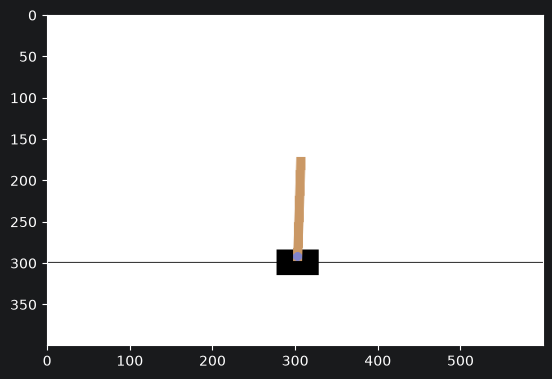

In [7]:
# Создаем сцену и выводим первый кадр
env = gym.make('CartPole-v1', render_mode='rgb_array')
obs, info = env.reset(seed=42)
frame = env.render()

plt.imshow(frame)

print(obs, frame.shape)

In [8]:
# Собираем цикл из 200 кадров
obs, info = env.reset(seed=42)
frames = [env.render()]
total_reward = 0
for step in range(200):
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = env.step(action.item())
    total_reward += reward
    frames.append(env.render())
    if terminated or truncated:
        break

print(f'{len(frames)}, {total_reward}')

201, 200.0


In [11]:
# Сохраняем в гиф
imageio.mimsave('cartpole.gif', frames, format='GIF', duration=20, loop=0)
env.close()

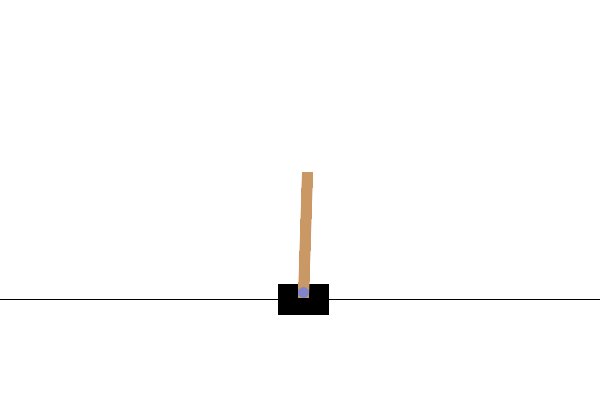

In [12]:
display(Image(filename='cartpole.gif'))

Використано готову модель PPO з Hugging Face для середовища CartPole-v1. Агент утримував жердину протягом 200 кроків і отримав винагороду 200. Кадри прогону збережено у GIF-анімацію.